In [1]:
import csv
import os
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, BatchNormalization, Softmax, Dropout, Bidirectional
import scipy.io  # to load MAT files
import time
import datetime
import sklearn
from matplotlib import pyplot as plt
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, train_test_split, GroupShuffleSplit
import sys
import scipy.signal as signal  # to downsample input data
from tensorflow.keras.callbacks import EarlyStopping
import scipy.stats
%matplotlib inline
%load_ext tensorboard

print('Tf Keras:', keras.__version__)
print('TensorFlow:', tf.__version__)
print('GPU device:', tf.test.gpu_device_name())

# Load the Drive helper and mount
from google.colab import drive
# This will prompt for authorization.
drive.mount('/content/drive')

if 'google.colab' in sys.modules:  # try to detect if we're running in colab or locally
  working_dir = '/content/drive/My Drive/TA/Perancangan model Human Activity Recognition/'
else:
  working_dir = '.'

log_dir_base = working_dir + '/logs/fit'

Tf Keras: 2.8.0
TensorFlow: 2.8.2
GPU device: /device:GPU:0
Mounted at /content/drive


In [ ]:
% pip install optuna

     |████████████████████████████████| 308 kB 5.4 MB/s 
     |████████████████████████████████| 80 kB 7.9 MB/s 
     |████████████████████████████████| 210 kB 39.9 MB/s 
     |████████████████████████████████| 75 kB 3.4 MB/s 
     |████████████████████████████████| 49 kB 4.8 MB/s 
     |████████████████████████████████| 149 kB 46.9 MB/s 
     |████████████████████████████████| 113 kB 40.4 MB/s 
  Created wheel for pyperclip: filename=pyperclip-1.8.2-py3-none-any.whl size=11137 sha256=fcfcf0710b9f84f6db7063e0bfdb4c21649381b0362d3172acf10ed17fff0e1c
  Stored in directory: /root/.cache/pip/wheels/9f/18/84/8f69f8b08169c7bae2dde6bd7daf0c19fca8c8e500ee620a28
Successfully built pyperclip


In [ ]:
#os.environ["CUDA_VISIBLE_DEVICES"]="-1"
import json
import h5py
import pickle
import optuna
from optuna.integration import TFKerasPruningCallback
from optuna.trial import TrialState

In [ ]:
dataset_dir = working_dir + 'LAR_dataset/'
dataset_acc = working_dir + 'LAR_ACC_Dataset/'
activity = ['Resting', 'No Resting']
subj_list = [1]
for category in activity:
    for subject in subj_list:
      for segment in range(1, 16):
        with open(f'{dataset_dir}/p{subject}/{category}/data ({segment}).csv', 'r') as csv_file:
          csv_reader = csv.reader(csv_file, delimiter=',')
          rows = []
          for row in csv_reader:
            rows.append(row)
          rows = np.array(rows)
          rowss = []
          for baris in range(1, 2601):
            rowss.append(rows[baris][2:5])
          rowss = np.array(rowss)
          rowsss = rowss.astype('float32')
          with open(f'{dataset_acc}/p{subject}/{category}/s{segment if segment>9 else "0" + str(segment)}.txt', 'w') as txt_file:
            np.savetxt(txt_file, rowsss, fmt='%.3f')
          txt_file.close()
        csv_file.close()

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:13: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  del sys.path[0]


In [ ]:
from sklearn.model_selection import KFold
kf = KFold(n_splits=8, random_state=0, shuffle=True)
for train_index, test_index in kf.split(x_data):
  print("TRAIN:", train_index, "TEST:", test_index)

In [ ]:
groups = []
for i in range(round(x_data.shape[0])):
  for j in range(4):
    groups.append(i)

np.array(groups).shape

(12120,)

In [ ]:
def create_dataset(window, overlap, distrib_stat=0):
  dataset_acc = working_dir + 'LAR_ACC_Dataset/'
  activity = ['Resting', 'No Resting']
  subj_list = [1]
  x_data = np.empty((0, window, 3))
  y_data = np.empty((0, 1))  # labels
  subj_inputs = []

  print('### creating dataset')
  tot_rows = 0
  for subject in subj_list:
    subj_inputs.append(0)
    for category, name in enumerate(activity):
      for segment in range(1, 16):
        with open(f'{dataset_acc}/p{subject}/{name}/s{segment if segment>9 else "0" + str(segment)}.txt', 'r') as file_data:
          fusion = np.loadtxt(file_data)
        tot_rows += len(fusion)
        fusion = clean_data(fusion)
        i = 0
        num_w = 0
        while i + window  <= len(fusion):
          i += (window - overlap)
          num_w += 1
        # compute actual windows
        x_data_part = np.empty((num_w, window, 3))  # preallocate
        i = 0
        for w in range(0, num_w):
          x_data_part[w] = fusion[i:i + window]
          i += (window - overlap)
        x_data = np.vstack((x_data, x_data_part))
        y_data = np.vstack((y_data, np.full((num_w, 1), category)))
        subj_inputs[-1] += num_w

  print('tot samples:', tot_rows)
  print('x_data:', x_data.shape)
  print('y_data:', y_data.shape)
  print('inputs per subject:', subj_inputs)

  if distrib_stat:
    n = sum(subj_inputs[:distrib_stat])
    print('class distribution (first', distrib_stat, 'subjects):', np.sum(y_data[:n] == 0), np.sum(y_data[:n] == 1))
  return x_data, y_data, subj_inputs

def clean_data(fusion):
  # some tracks have isolated NaNs
  fusion_nonull = np.empty((0,3))
  for row in range(len(fusion)):
    if not((fusion[row, 0] == 0) and (fusion[row, 1] == 0) and (fusion[row, 2] == 0)):
      fusion_nonull = np.vstack((fusion_nonull, fusion[row, :]))

  for col in range(0, 3):
    mean = np.mean(np.abs(fusion_nonull[:, col]))
    ids = np.where(np.isnan(fusion_nonull[:, col]))[0]
    for row in ids:
      fusion_nonull[row, col] = 0.5 * (fusion_nonull[row - 1, col] + fusion_nonull[row + 1, col])
    # many acc. tracks have periodic, single-point spikes of no specific values. Let's test all of them, even if it's slow
    for row in range(1, len(fusion_nonull) - 1):
      if abs(fusion_nonull[row, col] - fusion_nonull[row - 1, col]) > 20*mean and abs(fusion_nonull[row, col] - fusion_nonull[row + 1, col]) > 20*mean:
        fusion_nonull[row, col] = 0.5 * (fusion_nonull[row - 1, col] + fusion_nonull[row + 1, col])

  return fusion_nonull

def partition_data(subjects):
  # subjects = tuple (0-based)
  x_part = None
  y_part = None
  for subj in subjects:
    skip = sum(subj_inputs[:subj])
    num = subj_inputs[subj]
    xx = x_data[skip : skip + num]
    yy = y_data[skip : skip + num]
    if x_part is None:
      x_part = xx.copy()
      y_part = yy.copy()
    else:
      x_part = np.vstack((x_part, xx))  # vstack creates a copy of the data
      y_part = np.vstack((y_part, yy))

  y_part = tf.keras.utils.to_categorical(y_part, 2)
  return x_part, y_part

def create_model(window, dense1, lstm1, lstm2, lstm3, dropout = 0.2):
  print("### creating model")
  model = keras.Sequential()

  model.add(keras.Input(shape = (window, 3)))
  if dense1: model.add(Dense(dense1, name = 'dense1'))
  model.add(BatchNormalization(name = 'norm'))
  model.add(LSTM(lstm1, return_sequences = bool(lstm2), name = 'lstm1'))
  if lstm2:
    model.add(Dropout(dropout, name = 'drop2'))
    model.add(LSTM(lstm2, return_sequences = bool(lstm3), name = 'lstm2'))
  if lstm3:
    model.add(Dropout(dropout, name = 'drop3'))
    model.add(LSTM(lstm3, name = 'lstm3'))
  model.add(Dropout(dropout, name = 'drop4'))
  model.add(Dense(2, activation='softmax', name = 'dense2'))
  model.compile(loss = 'categorical_crossentropy', optimizer = 'adam',
                metrics = ['accuracy'])
  model.summary()
  return model

def train_session():

  kf = KFold(n_splits=10)
  gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=0)
  gss.get_n_splits()

  

  for train_index, test_index in kf.split(x_data):
    for iter in range(0, iterations):
      model = create_model(window, dense1, lstm1, lstm2, lstm3)

      # model training
      # x_data_train, y_data_train = partition_data(permutation[0])  # train subjects
      # x_data_val, y_data_val = partition_data(permutation[1])  # validation subjects, can be None
      x_data_train = x_data[train_index]
      y_data_train = tf.keras.utils.to_categorical(y_data[train_index], 2)
      x_data_val = x_data[test_index]
      y_data_val = tf.keras.utils.to_categorical(y_data[test_index], 2)
      print(f'### training with {len(x_data_train)} inputs, {len(x_data_val) if x_data_val is not None else 0} validation')

      early_stopping = EarlyStopping(
        monitor='val_accuracy', 
        patience=10, 
        min_delta=0.01, 
        mode='max',
        restore_best_weights=True
      )

      # train
      start_time = time.monotonic()
      history = model.fit(x_data_train, y_data_train,
        epochs=epochs, validation_data = (x_data_val, y_data_val) if x_data_val is not None else None,
        callbacks=[early_stopping],
        verbose=1)

      time_train = time.monotonic() - start_time

      # model test
      # x_data_test, y_data_test = partition_data(subjs_test)

      print(f'### testing with {len(x_data_val)} inputs')
      start_time = time.monotonic()
      eval_metrics = model.evaluate(x_data_val, y_data_val)
      # eval_metrics = model.evaluate(x_data_val, y_data_val)
      time_test = time.monotonic() - start_time
      # save in both directory and h5 formats (we had problems with both of them sometimes)
      model_file_name = f'{working_dir}/our_model/model_w{window:04d}_o{overlap:03d}_e{epochs}_t{round(eval_metrics[1] * 10000)}'
      #model.save(model_file_name)
      model.save(model_file_name + '.h5')

In [ ]:
if __name__ == '__main__':
  window = 100
  overlap = 80
  x_data, y_data, subj_inputs = create_dataset(window, overlap, distrib_stat = 1)

### creating dataset
tot samples: 78000
x_data: (3780, 100, 3)
y_data: (3780, 1)
inputs per subject: [3780]
class distribution (first 1 subjects): 1890 1890


In [ ]:
inputs = np.empty((0,3))
for i in range(x_data.shape[0]):
  inputs = np.concatenate((inputs, x_data[i, :, :]), axis=0)
inputs.shape

(303000, 3)

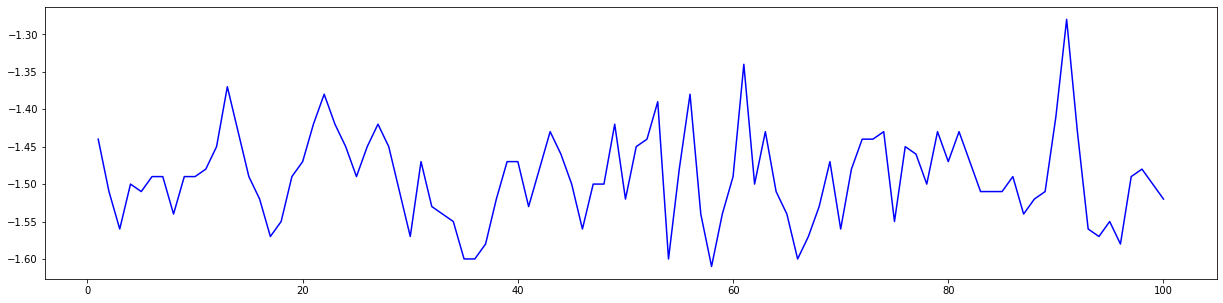

In [ ]:
a = 0
b = a + 1
po = 100

f = plt.figure()
f.set_figwidth(21)
f.set_figheight(5)
# plt.plot(np.arange(1, 4000+1), PPG1[0:4000], color='red')
plt.plot(np.arange(1, po+1), x_data[0, po*a:po*b, 0], color='blue')
# plt.plot(widthpeaks_sys, sys_peak, "o")
# plt.plot(widthpeaks_dia, dia_peak, "x")
plt.show()

In [ ]:
# create and train model
if __name__ == '__main__':
  dense1 = 32
  lstm1 = 32
  lstm2 = 32
  lstm3 = 32
  # subjs_train_perm = ( ((0, 1, 2, 3, 4, 5), ()), )  # final model
  # subjs_train_perm = ( ((0, 1, 2, 3, 4), (6,)), ((0, 1, 2, 3, 6), (4,)), ((0, 1, 2, 4, 6), (3,)), ((0, 1, 3, 4, 6), (2,)), ((0, 2, 3, 4, 6), (1,)), ((1, 2, 3, 4, 6), (0,)))  # final model
  # subjs_test = (5, 7)
  epochs = 50
  iterations = 1  # repeat every test to cope with randomness
  train_session()

### creating model
Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense1 (Dense)              (None, 100, 32)           128       
                                                                 
 norm (BatchNormalization)   (None, 100, 32)           128       
                                                                 
 lstm1 (LSTM)                (None, 100, 32)           8320      
                                                                 
 drop2 (Dropout)             (None, 100, 32)           0         
                                                                 
 lstm2 (LSTM)                (None, 100, 32)           8320      
                                                                 
 drop3 (Dropout)             (None, 100, 32)           0         
                                                                 
 lstm3 (LSTM)                (None,

In [ ]:
y_pred_batch = model.predict(x_data_test)
y_pred = np.argmax(y_pred_batch,axis=-1)
y_data_rvs = tf.math.argmax(y_data_test, axis=1)
y_data_rvs = np.array(y_data_rvs)
y_kl = tf.keras.utils.to_categorical(y_pred, 4)
type(y_data_rvs), type(y_pred)

(numpy.ndarray, numpy.ndarray)

In [ ]:
# model test only
if __name__ == '__main__':
  model = keras.models.load_model(f'{working_dir}/our_model/2_64/model_w0100_o080_e50_t10000.h5')
  eval_metrics = model.evaluate(x_data, tf.keras.utils.to_categorical(y_data, 2))

119/119 [==============================] - 2s 9ms/step - loss: 0.0082 - accuracy: 0.9984


In [ ]:
run_model = tf.function(lambda x: model(x))
BATCH_SIZE = 1
STEPS = 100
INPUT_SIZE = 3
concrete_func = run_model.get_concrete_function(
    tf.TensorSpec([BATCH_SIZE, STEPS, INPUT_SIZE], model.inputs[0].dtype))
model.save(working_dir + 'our_model/saved_models/LSTM_model',signatures = concrete_func)

INFO:tensorflow:Assets written to: /content/drive/My Drive/TA/Perancangan model Human Activity Recognition/our_model/saved_models/LSTM_model/assets


INFO:tensorflow:Assets written to: /content/drive/My Drive/TA/Perancangan model Human Activity Recognition/our_model/saved_models/LSTM_model/assets


In [ ]:
model = tf.keras.models.load_model(f'{working_dir}/our_model/2_64/model_w0100_o080_e50_t10000.h5')
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS, tf.lite.OpsSet.SELECT_TF_OPS]
converter._experimental_lower_tensor_list_ops = False
tflite_model = converter.convert()
open(working_dir + 'our_model/tensorflowlite_model/model_HAR_RNNLSTM_ACC_new.tflite', "wb").write(tflite_model)

INFO:tensorflow:Assets written to: /tmp/tmpnzpfcqwt/assets


INFO:tensorflow:Assets written to: /tmp/tmpnzpfcqwt/assets


691224